**Notebook 10: H3 CICIDS2017 Operational Validation**


H3 CICIDS2017 Operational Validation

H3: Cybersecurity analytics reduces the operational impact of simulated denial-of-service conditions in RFID baggage tracking environments.

RQ3: How effective are cybersecurity analytics in reducing denial-of-service risks in baggage tracking?

This notebook checks how a network attack detector performs and what happens when simulated baggage scan recovery depends on an alert. The network data comes from CICIDS2017. The baggage scan data is simulated. They are not records from the same operating system.

BLUF: The notebook compares buffering with recovery that requires an analytics alert. It checks whether the alert improves scan recovery in the simulation.


Step 1: Connect and Review the RFID Data

The prepared baggage scan file is opened. The notebook checks the number of scans, bags, and denial of service events before running the H3 tests.


In [1]:

# Step 1: Connect and review the prepared RFID data


# Load the libraries

import pandas as pd
import os


# Set the main project folder

main_folder = os.getcwd()


# Check the project folder

if not os.path.isdir(main_folder + "/06_Prepared_Data"):
    main_folder = os.path.dirname(main_folder)


# Set the prepared data folder

prepared_folder = main_folder + "/06_Prepared_Data"


# Set the prepared RFID file

prepared_file = (
    prepared_folder +
    "/02_Prepared_RFID_Data.csv"
)


# Load the prepared RFID data

h3_data = pd.read_csv(prepared_file)

print("The prepared RFID data is connected.")


# Check the dataset size

print(
    "\nTotal RFID records:",
    len(h3_data)
)

print(
    "Total columns:",
    len(h3_data.columns)
)

print(
    "Total baggage journeys:",
    h3_data["bag_id"].nunique()
)

print(
    "Unique scan IDs:",
    h3_data["scan_id"].nunique()
)


# Check the denial of service records

print(
    "\nDenial of Service scans:",
    (h3_data["scan_status"] == "Denial of Service").sum()
)

print(
    "DoS disruption records:",
    (h3_data["disruption_window"] == 1).sum()
)


# Create a separate copy of the known DoS events

dos_events = h3_data[
    h3_data["disruption_window"] == 1
].copy()


# Check the affected baggage journeys and disruption groups

print(
    "Unique affected scans:",
    dos_events["scan_id"].nunique()
)

print(
    "Affected baggage journeys:",
    dos_events["bag_id"].nunique()
)

print(
    "Unique disruption IDs:",
    dos_events["disruption_id"].nunique()
)


print("\nStep 1 complete.")


The prepared RFID data is connected.

Total RFID records: 31575
Total columns: 34
Total baggage journeys: 5000
Unique scan IDs: 31575

Denial of Service scans: 75
DoS disruption records: 75
Unique affected scans: 75
Affected baggage journeys: 75
Unique disruption IDs: 10

Step 1 complete.


Step 2: Review the Simulated Disruptions

The simulation contains 75 affected scans in 10 disruption groups. The notebook counts the scans and bags in each group and checks how long the simulated disruptions last. The original prepared file is not changed.


In [2]:

# Step 2: Review the simulated DoS disruptions


# Create a separate copy of the DoS records

h3_disruptions = dos_events.copy()


# Count the affected scans and baggage journeys
# for each simulated disruption

disruption_summary = (
    h3_disruptions
    .groupby("disruption_id")
    .agg(
        affected_scans=("scan_id", "count"),
        affected_journeys=("bag_id", "nunique"),
        duration_minutes=("disruption_minutes", "first")
    )
    .reset_index()
)


# Display the disruption results

print("H3 DoS disruption data reviewed.")

print("\nDisruption summary:")

print(
    disruption_summary.to_string(index=False)
)


# Confirm the total number of disruptions

print(
    "\nTotal DoS disruptions:",
    len(disruption_summary)
)

print(
    "Total affected scans:",
    disruption_summary["affected_scans"].sum()
)

print(
    "Total affected baggage journeys:",
    h3_disruptions["bag_id"].nunique()
)


# Check that each disruption has one duration

duration_check = (
    h3_disruptions
    .groupby("disruption_id")["disruption_minutes"]
    .nunique()
)

print(
    "Consistent disruption durations:",
    (duration_check == 1).all()
)


# Confirm the original RFID data remains unchanged

print(
    "\nOriginal RFID records:",
    len(h3_data)
)

print("\nStep 2 complete.")


H3 DoS disruption data reviewed.

Disruption summary:
disruption_id  affected_scans  affected_journeys  duration_minutes
        DOS01               8                  8                20
        DOS02               8                  8                16
        DOS03               8                  8                27
        DOS04               8                  8                29
        DOS05               8                  8                20
        DOS06               7                  7                17
        DOS07               7                  7                21
        DOS08               7                  7                17
        DOS09               7                  7                23
        DOS10               7                  7                17

Total DoS disruptions: 10
Total affected scans: 75
Total affected baggage journeys: 75
Consistent disruption durations: True

Original RFID records: 31575

Step 2 complete.


Step 3: Check Network Attack Detection

The Friday afternoon CICIDS2017 file contains labeled normal and attack traffic. Logistic Regression is trained to tell those records apart using five network measurements. Seventy percent of the records are used for training and 30 percent for testing. The results show how often the network model finds attacks and makes mistakes. The network traffic is separate from the baggage scan records.


In [3]:

# Step 3: CICIDS2017 denial of service detection analysis


# Load the libraries

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


# Connect to the downloaded CICIDS2017 file

cicids_file = os.path.join(
    main_folder,
    "05_CICIDS2017",
    "data",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

if not os.path.exists(cicids_file):
    raise FileNotFoundError(cicids_file)


# Select five network traffic measurements

h3_features = [
    "Flow Duration",
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets"
]


# Load the network traffic data

h3_network = pd.read_csv(
    cicids_file,
    usecols=lambda name: name.strip() in h3_features + ["Label"]
)

h3_network.columns = h3_network.columns.str.strip()


# Prepare the traffic labels

h3_network["Label"] = (
    h3_network["Label"].astype(str).str.strip().str.upper()
)

print("CICIDS2017 network data connected.")

print("\nTotal network records:", len(h3_network))

print("\nNetwork traffic labels:")
print(h3_network["Label"].value_counts())


# Confirm the expected labels are present

if set(h3_network["Label"].unique()) != {"BENIGN", "DDOS"}:
    raise ValueError("Unexpected network traffic labels.")


# Prepare the model inputs

X = h3_network[h3_features].apply(
    pd.to_numeric,
    errors="coerce"
)

X = X.replace([np.inf, -np.inf], np.nan)


# Identify the known DDoS records
# 0 means benign and 1 means DDoS

y = (h3_network["Label"] == "DDOS").astype(int)


# Divide the data into training and testing records

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# Prepare the Logistic Regression model

h3_detector = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])


# Train the model using the training records

h3_detector.fit(X_train, y_train)


# Test the model using records not used for training

h3_predictions = h3_detector.predict(X_test)

h3_probabilities = h3_detector.predict_proba(X_test)[:, 1]


# Calculate the detection results

h3_accuracy = accuracy_score(y_test, h3_predictions)

h3_balanced_accuracy = balanced_accuracy_score(
    y_test, h3_predictions
)

h3_precision = precision_score(y_test, h3_predictions)

h3_recall = recall_score(y_test, h3_predictions)

h3_f1 = f1_score(y_test, h3_predictions)

h3_auc = roc_auc_score(y_test, h3_probabilities)


# Display the detection results

print("\nCICIDS2017 detection results:")

print("Accuracy:", round(h3_accuracy, 4))
print("Balanced accuracy:", round(h3_balanced_accuracy, 4))
print("Precision:", round(h3_precision, 4))
print("Recall:", round(h3_recall, 4))
print("F1 score:", round(h3_f1, 4))
print("ROC AUC:", round(h3_auc, 4))


# Review the confusion matrix

tn, fp, fn, tp = confusion_matrix(
    y_test, h3_predictions
).ravel()

print("\nConfusion matrix results:")

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)


# Compare the model with a simple baseline
# The baseline labels every record as an attack

baseline_predictions = np.ones(len(y_test))

print("\nAlways attack baseline:")

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test, baseline_predictions), 4)
)

print(
    "F1 score:",
    round(f1_score(y_test, baseline_predictions), 4)
)


# Keep the test predictions for the next experiment

h3_detection_test = pd.DataFrame({
    "actual_attack": y_test.to_numpy(),
    "predicted_attack": h3_predictions,
    "attack_probability": h3_probabilities
})


print("\nStep 3 complete.")
print("Original dataset remains unchanged.")


CICIDS2017 network data connected.

Total network records: 225745

Network traffic labels:
Label
DDOS      128027
BENIGN     97718
Name: count, dtype: int64

Training records: 158021
Testing records: 67724

CICIDS2017 detection results:
Accuracy: 0.6498
Balanced accuracy: 0.6479
Precision: 0.7031
Recall: 0.6621
F1 score: 0.682
ROC AUC: 0.7885

Confusion matrix results:
True negatives: 18577
False positives: 10739
False negatives: 12979
True positives: 25429

Always attack baseline:
Balanced accuracy: 0.5
F1 score: 0.7238

Step 3 complete.
Original dataset remains unchanged.


Step 4: Compare Three Recovery Conditions

The same 75 affected baggage scans are tested with no recovery, store and forward buffering, and recovery that requires an analytics alert. The buffering chance is set to 90 percent and the restoration chance to 95 percent. One network detection result is assigned to each of the 10 simulated disruptions. This link is part of the simulation; it was not observed in a real airport.


In [4]:

# Step 4: Apply the supplemental H3 mitigation conditions

# Load NumPy

import numpy as np

# Create a separate working copy of the affected RFID scans

h3_comparison = dos_events.copy()

# Set the original H3 random state

np.random.seed(42)

# Create the buffering and recovery fields

h3_comparison["buffer_indicator"] = 0

h3_comparison["store_forward_restored"] = 0

# Apply the 90% buffering probability

buffer_draw = np.random.random(
    len(h3_comparison)
)

buffered_index = h3_comparison.index[
    buffer_draw < 0.90
]

h3_comparison.loc[
    buffered_index,
    "buffer_indicator"
] = 1

# Apply the 95% restoration probability

restore_draw = np.random.random(
    len(buffered_index)
)

recovered_index = buffered_index[
    restore_draw < 0.95
]

h3_comparison.loc[
    recovered_index,
    "store_forward_restored"
] = 1

# Select the actual DDoS predictions from Step 3

attack_results = h3_detection_test[
    h3_detection_test["actual_attack"] == 1
].copy()

# Identify the 10 simulated disruption groups

disruption_alerts = h3_comparison[
    ["disruption_id"]
].drop_duplicates().copy()

# Use a separate random state for the detection decisions

np.random.seed(43)

# Assign one detection decision to each disruption

disruption_alerts["analytics_alert"] = np.random.choice(
    attack_results["predicted_attack"],
    size=len(disruption_alerts)
)

# Add the detection decisions to the affected RFID scans

h3_comparison = h3_comparison.merge(
    disruption_alerts,
    on="disruption_id",
    how="left"
)

# Apply analytics triggered recovery

h3_comparison["analytics_restored"] = (
    (h3_comparison["store_forward_restored"] == 1)
    &
    (h3_comparison["analytics_alert"] == 1)
).astype(int)

# Count the restored RFID scans

total_events = len(h3_comparison)

buffer_restored = h3_comparison[
    "store_forward_restored"
].sum()

analytics_restored = h3_comparison[
    "analytics_restored"
].sum()

# Calculate permanent event losses

baseline_lost = total_events

buffer_lost = total_events - buffer_restored

analytics_lost = total_events - analytics_restored

# Create the comparison table

h3_results = pd.DataFrame({
    "Condition": [
        "No mitigation",
        "Store and forward",
        "Analytics triggered"
    ],
    "Restored Events": [
        0,
        buffer_restored,
        analytics_restored
    ],
    "Permanent Losses": [
        baseline_lost,
        buffer_lost,
        analytics_lost
    ]
})

# Display the comparison results

print("H3 supplemental mitigation conditions created.")

print("\nH3 mitigation comparison:")

print(
    h3_results.to_string(index=False)
)

# Review the detection decisions

print(
    "\nDisruptions detected:",
    disruption_alerts["analytics_alert"].sum()
)

print(
    "Disruptions missed:",
    (disruption_alerts["analytics_alert"] == 0).sum()
)

# Confirm the original prepared data remains unchanged

print(
    "\nOriginal RFID records:",
    len(h3_data)
)

print("\nStep 4 complete.")


H3 supplemental mitigation conditions created.

H3 mitigation comparison:
          Condition  Restored Events  Permanent Losses
      No mitigation                0                75
  Store and forward               64                11
Analytics triggered               57                18

Disruptions detected: 9
Disruptions missed: 1

Original RFID records: 31575

Step 4 complete.


Step 5: Check and Save the Recovery Results

The notebook counts recovered scans, lost scans, and incomplete bag journeys for each condition. It also reviews false network alerts. All three conditions use the same 75 scans. The new results are saved separately from the original H3 experiment.


In [5]:

# Step 5: Validate and save the H3 results

# Load the library

import os

# Calculate the recovery percentages

h3_results["Recovery Rate (%)"] = (
    h3_results["Restored Events"] / 75 * 100
).round(2)

# Count incomplete baggage journeys

buffer_incomplete = h3_comparison.loc[
    h3_comparison["store_forward_restored"] == 0,
    "bag_id"
].nunique()

analytics_incomplete = h3_comparison.loc[
    h3_comparison["analytics_restored"] == 0,
    "bag_id"
].nunique()

# Add incomplete journeys to the comparison

h3_results["Incomplete Journeys"] = [
    75,
    buffer_incomplete,
    analytics_incomplete
]

# Display the comparison

print("H3 supplemental results validated.")

print("\nH3 mitigation comparison:")

print(h3_results.to_string(index=False))

# Review false positive detections from CICIDS2017

benign_results = h3_detection_test[
    h3_detection_test["actual_attack"] == 0
]

false_positives = (
    benign_results["predicted_attack"] == 1
).sum()

false_positive_rate = (
    false_positives / len(benign_results) * 100
)

print("\nCICIDS2017 false positive results:")

print("Benign test records:", len(benign_results))

print("False positive detections:", false_positives)

print(
    "False positive rate:",
    round(false_positive_rate, 2),
    "%"
)

# Validate the RFID event population

print("\nH3 validation checks:")

print(
    "Affected scans verified:",
    len(h3_comparison) == 75
)

print(
    "Disruption groups verified:",
    h3_comparison["disruption_id"].nunique() == 10
)

print(
    "Original RFID data preserved:",
    len(h3_data) == 31575
)

# Confirm analytics did not recover events
# that store and forward failed to recover

recovery_check = (
    h3_comparison["analytics_restored"]
    <= h3_comparison["store_forward_restored"]
).all()

print(
    "Analytics recovery check:",
    recovery_check
)

# Stop if the recovery comparison is inconsistent

if not recovery_check:
    raise ValueError("Recovery validation failed.")

# Save the results to the existing H3 results folder

results_folder = os.path.join(
    main_folder,
    "09_H3_Results"
)

os.makedirs(results_folder, exist_ok=True)

# Save the comparison table

h3_results.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_comparison.csv"
    ),
    index=False
)

# Save the affected RFID event results

h3_comparison.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_event_results.csv"
    ),
    index=False
)

print("\nSupplemental H3 results saved.")

print("\nStep 5 complete.")


H3 supplemental results validated.

H3 mitigation comparison:
          Condition  Restored Events  Permanent Losses  Recovery Rate (%)  Incomplete Journeys
      No mitigation                0                75               0.00                   75
  Store and forward               64                11              85.33                   11
Analytics triggered               57                18              76.00                   18

CICIDS2017 false positive results:
Benign test records: 29316
False positive detections: 10739
False positive rate: 36.63 %

H3 validation checks:
Affected scans verified: True
Disruption groups verified: True
Original RFID data preserved: True
Analytics recovery check: True

Supplemental H3 results saved.

Step 5 complete.


Step 6: Check Recovery Time

A recovery delay of 1 to 5 minutes is added to restored scans. The total time a record is out of date includes the disruption time and this recovery delay. Lost records are not given recovery times. These are simulated delays, and extra time spent detecting an attack was not added.


In [6]:

# Step 6: Evaluate recovery time and record staleness

# Use a separate random seed for recovery timing

np.random.seed(44)

# Generate recovery processing delays from 1 to 5 minutes

h3_comparison["recovery_delay_minutes"] = np.random.randint(
    1,
    6,
    size=len(h3_comparison)
)

# Identify the events restored under each condition

store_restored = (
    h3_comparison["store_forward_restored"] == 1
)

analytics_restored = (
    h3_comparison["analytics_restored"] == 1
)

# Create the record staleness fields

h3_comparison["store_staleness_minutes"] = np.nan

h3_comparison["analytics_staleness_minutes"] = np.nan

# Calculate record staleness for store and forward

h3_comparison.loc[
    store_restored,
    "store_staleness_minutes"
] = (
    h3_comparison.loc[store_restored, "disruption_minutes"]
    + h3_comparison.loc[store_restored, "recovery_delay_minutes"]
)

# Calculate record staleness for analytics triggered recovery

h3_comparison.loc[
    analytics_restored,
    "analytics_staleness_minutes"
] = (
    h3_comparison.loc[analytics_restored, "disruption_minutes"]
    + h3_comparison.loc[analytics_restored, "recovery_delay_minutes"]
)

# Calculate the average recovery processing delays

store_delay = h3_comparison.loc[
    store_restored,
    "recovery_delay_minutes"
].mean()

analytics_delay = h3_comparison.loc[
    analytics_restored,
    "recovery_delay_minutes"
].mean()

# Calculate the average record staleness

store_staleness = h3_comparison[
    "store_staleness_minutes"
].mean()

analytics_staleness = h3_comparison[
    "analytics_staleness_minutes"
].mean()

# Create the recovery timing comparison

h3_timing = pd.DataFrame({
    "Condition": [
        "Store and forward",
        "Analytics triggered"
    ],
    "Restored Events": [
        int(store_restored.sum()),
        int(analytics_restored.sum())
    ],
    "Mean Recovery Delay": [
        store_delay,
        analytics_delay
    ],
    "Mean Record Staleness": [
        store_staleness,
        analytics_staleness
    ]
})

# Display the recovery timing results

print("H3 recovery timing analysis complete.")

print("\nRecovery timing comparison:")

print(h3_timing.round(2).to_string(index=False))

# Save the recovery timing summary

h3_timing.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_timing_summary.csv"
    ),
    index=False
)

# Update the supplemental event results with timing fields

h3_comparison.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_event_results.csv"
    ),
    index=False
)

print("\nRecovery timing results saved.")

print("\nStep 6 complete.")


H3 recovery timing analysis complete.

Recovery timing comparison:
          Condition  Restored Events  Mean Recovery Delay  Mean Record Staleness
  Store and forward               64                 2.94                  23.58
Analytics triggered               57                 2.98                  23.70

Recovery timing results saved.

Step 6 complete.


Step 7: Check the Network Detection Assumptions

The model finds some attacks and misses others. The notebook compares its measured detection rate with the alerts assigned to the 10 simulated disruptions. It also estimates how many scans would be recovered using the measured detection rate. This is an estimate, not another set of recovered scans. False alerts are reviewed separately.


In [7]:

# Step 7: Validate the analytics detection assumptions

# Review the actual CICIDS2017 attack predictions

attack_results = h3_detection_test[
    h3_detection_test["actual_attack"] == 1
]

# Calculate the actual attack detection rate

detection_rate = attack_results[
    "predicted_attack"
].mean()

# Calculate the detection rate assigned to the 10 disruptions

simulated_detection_rate = disruption_alerts[
    "analytics_alert"
].mean()

# Review the store and forward recovery results

store_recovered = h3_comparison[
    "store_forward_restored"
].sum()

analytics_recovered = h3_comparison[
    "analytics_restored"
].sum()

total_events = len(h3_comparison)

# Estimate recovery using the measured detection rate
# This assumes detection and buffering success are independent

expected_recovered = store_recovered * detection_rate

expected_losses = total_events - expected_recovered

# Display the detection comparison

print("H3 detection assumptions reviewed.")

print(
    "\nCICIDS2017 detection rate:",
    round(detection_rate * 100, 2),
    "%"
)

print(
    "Simulated disruption detection rate:",
    round(simulated_detection_rate * 100, 2),
    "%"
)

# Display the recovery comparison

print("\nH3 recovery sensitivity results:")

print(
    "Store and forward restored:",
    store_recovered
)

print(
    "Single simulation analytics restored:",
    analytics_recovered
)

print(
    "Expected analytics restored:",
    round(expected_recovered, 2)
)

print(
    "Expected permanent losses:",
    round(expected_losses, 2)
)

print(
    "Expected analytics recovery rate:",
    round(expected_recovered / total_events * 100, 2),
    "%"
)

print("\nStep 7 complete.")


H3 detection assumptions reviewed.

CICIDS2017 detection rate: 66.21 %
Simulated disruption detection rate: 90.0 %

H3 recovery sensitivity results:
Store and forward restored: 64
Single simulation analytics restored: 57
Expected analytics restored: 42.37
Expected permanent losses: 32.63
Expected analytics recovery rate: 56.5 %

Step 7 complete.


Step 8: Review the H3 Sensitivity Results

Store and forward buffering restored 64 of the 75 affected scans. Recovery that required an analytics alert restored 57 scans in this test. The network model detected 66.21 percent of attack records. Applying that rate to the buffering results gives an estimate of 42.37 restored scans, or 56.50 percent of all affected scans.

Buffering reduced losses, but requiring an analytics alert did not improve recovery. The network model also produced false alarms. These findings do not confirm an added recovery benefit from analytics under the tested assumptions.


In [8]:

# Step 8: Save the final H3 sensitivity results

# Create the detection sensitivity summary

h3_sensitivity = pd.DataFrame({
    "Measurement": [
        "CICIDS2017 detection rate (%)",
        "Simulated detection rate (%)",
        "Store and forward restored",
        "Analytics restored",
        "Expected analytics restored",
        "Expected permanent losses",
        "Expected analytics recovery rate (%)",
        "False positive rate (%)"
    ],
    "Result": [
        round(detection_rate * 100, 2),
        round(simulated_detection_rate * 100, 2),
        int(store_recovered),
        int(analytics_recovered),
        round(expected_recovered, 2),
        round(expected_losses, 2),
        round(expected_recovered / total_events * 100, 2),
        round(false_positive_rate, 2)
    ]
})

# Display the final results

print("H3 detection sensitivity summary:")

print(h3_sensitivity.to_string(index=False))

# Save the summary in the H3 results folder

h3_sensitivity.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_detection_sensitivity.csv"
    ),
    index=False
)

print("\nFinal H3 sensitivity results saved.")

print("\nStep 8 complete.")


H3 detection sensitivity summary:
                         Measurement  Result
       CICIDS2017 detection rate (%)   66.21
        Simulated detection rate (%)   90.00
          Store and forward restored   64.00
                  Analytics restored   57.00
         Expected analytics restored   42.37
           Expected permanent losses   32.63
Expected analytics recovery rate (%)   56.50
             False positive rate (%)   36.63

Final H3 sensitivity results saved.

Step 8 complete.


Step 9: Show the Recovery Results

The figure compares recovery percentages for no recovery, store and forward buffering, and recovery that requires an analytics alert. It shows the single simulated test. The estimated result from Step 8 is separate and should not be read as another observed recovery result.


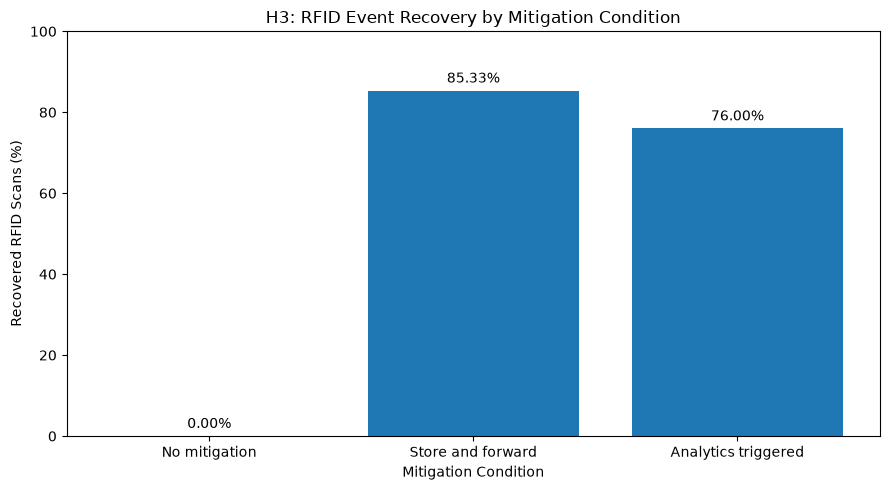

H3 recovery comparison chart saved.

Step 9 complete.


In [9]:

# Step 9: Visualize the H3 mitigation results

# Load the plotting library

import matplotlib.pyplot as plt

# Create the recovery comparison chart

plt.figure(figsize=(9, 5))

plt.bar(
    h3_results["Condition"],
    h3_results["Recovery Rate (%)"]
)

# Add the chart title and labels

plt.title("H3: RFID Event Recovery by Mitigation Condition")

plt.xlabel("Mitigation Condition")

plt.ylabel("Recovered RFID Scans (%)")

plt.ylim(0, 100)

# Display the recovery percentage above each bar

for i, value in enumerate(h3_results["Recovery Rate (%)"]):
    plt.text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

# Save the chart for Chapter 4

plt.tight_layout()

plt.savefig(
    os.path.join(
        results_folder,
        "h3_supplemental_recovery_comparison.png"
    ),
    dpi=300
)

# Display the chart

plt.show()

print("H3 recovery comparison chart saved.")

print("\nStep 9 complete.")


Step 10: Review the H3 Findings

The test used 75 affected scans across 10 simulated disruptions. Buffering restored 64 scans, or 85.33 percent. Recovery requiring an analytics alert restored 57 scans, or 76.00 percent.

The network model found 66.21 percent of attacks but incorrectly flagged 36.63 percent of normal traffic as attacks. The estimated analytics recovery rate was 56.50 percent when the measured detection rate was applied.

The extra alert requirement did not outperform buffering alone. H3 was not independently confirmed as an added analytics benefit. The network model and baggage recovery used different datasets connected by simulation assumptions.


In [10]:

# Step 10: Review and save the final H3 research findings

# Create the final H3 results table

h3_final_results = pd.DataFrame({
    "Measurement": [
        "Affected RFID scans",
        "DoS disruptions",
        "Store and forward restored",
        "Analytics restored",
        "Store and forward recovery (%)",
        "Analytics recovery (%)",
        "CICIDS2017 detection rate (%)",
        "CICIDS2017 false positive rate (%)",
        "Expected analytics recovery (%)"
    ],
    "Result": [
        total_events,
        len(disruption_alerts),
        int(store_recovered),
        int(analytics_recovered),
        round(store_recovered / total_events * 100, 2),
        round(analytics_recovered / total_events * 100, 2),
        round(detection_rate * 100, 2),
        round(false_positive_rate, 2),
        round(expected_recovered / total_events * 100, 2)
    ]
})

# Display the final results

print("Final H3 research results:")

print(h3_final_results.to_string(index=False))

# Save the final results table

h3_final_results.to_csv(
    os.path.join(
        results_folder,
        "h3_supplemental_final_results.csv"
    ),
    index=False
)

# Record the research conclusion

h3_conclusion = (
    "H3 was not independently confirmed as an added benefit "
    "of cybersecurity analytics. Store and forward buffering "
    "recovered more RFID scans than analytics triggered recovery. "
    "The results are simulated and do not represent observed "
    "airport recovery performance."
)

# Display the conclusion

print("\nH3 research conclusion:")

print(h3_conclusion)

# Save the research conclusion

with open(
    os.path.join(
        results_folder,
        "h3_supplemental_conclusion.txt"
    ),
    "w"
) as file:
    file.write(h3_conclusion)

print("\nFinal H3 results saved.")

print("\nStep 10 complete.")


Final H3 research results:
                       Measurement  Result
               Affected RFID scans   75.00
                   DoS disruptions   10.00
        Store and forward restored   64.00
                Analytics restored   57.00
    Store and forward recovery (%)   85.33
            Analytics recovery (%)   76.00
     CICIDS2017 detection rate (%)   66.21
CICIDS2017 false positive rate (%)   36.63
   Expected analytics recovery (%)   56.50

H3 research conclusion:
H3 was not independently confirmed as an added benefit of cybersecurity analytics. Store and forward buffering recovered more RFID scans than analytics triggered recovery. The results are simulated and do not represent observed airport recovery performance.

Final H3 results saved.

Step 10 complete.


Step 11: Verify the Saved H3 Results

The notebook checks that the result files and recovery figure were saved. It also checks that the original RFID data was not changed and that the same 75 affected scans and 10 disruptions were used throughout the test.


In [11]:

# Step 11: Verify the completed H3 research files

# List the saved H3 research files

h3_files = [
    "h3_supplemental_comparison.csv",
    "h3_supplemental_event_results.csv",
    "h3_supplemental_timing_summary.csv",
    "h3_supplemental_detection_sensitivity.csv",
    "h3_supplemental_recovery_comparison.png",
    "h3_supplemental_final_results.csv",
    "h3_supplemental_conclusion.txt"
]

# Check that each research file exists

print("H3 research file verification:")

for filename in h3_files:
    file_path = os.path.join(results_folder, filename)

    if os.path.isfile(file_path):
        print("Saved:", filename)
    else:
        print("Missing:", filename)

# Confirm all seven research files were saved

saved_files = sum(
    os.path.isfile(os.path.join(results_folder, filename))
    for filename in h3_files
)

print("\nResearch files saved:", saved_files, "of", len(h3_files))

# Verify the original RFID dataset

print("\nOriginal RFID records:", len(h3_data))

print("Original baggage journeys:", h3_data["bag_id"].nunique())

# Verify the supplemental H3 population

print("\nAffected RFID scans:", len(h3_comparison))

print(
    "Affected baggage journeys:",
    h3_comparison["bag_id"].nunique()
)

print(
    "Simulated DoS disruptions:",
    h3_comparison["disruption_id"].nunique()
)

# Verify the final recovery results

print("\nStore and forward restored:", int(store_recovered))

print("Analytics triggered restored:", int(analytics_recovered))

# Confirm the research files and results agree

validation_passed = (
    saved_files == len(h3_files)
    and len(h3_data) == 31575
    and len(h3_comparison) == 75
    and h3_comparison["disruption_id"].nunique() == 10
    and int(store_recovered) == 64
    and int(analytics_recovered) == 57
)

print("\nFinal H3 verification passed:", validation_passed)

print("\nStep 11 complete.")


H3 research file verification:
Saved: h3_supplemental_comparison.csv
Saved: h3_supplemental_event_results.csv
Saved: h3_supplemental_timing_summary.csv
Saved: h3_supplemental_detection_sensitivity.csv
Saved: h3_supplemental_recovery_comparison.png
Saved: h3_supplemental_final_results.csv
Saved: h3_supplemental_conclusion.txt

Research files saved: 7 of 7

Original RFID records: 31575
Original baggage journeys: 5000

Affected RFID scans: 75
Affected baggage journeys: 75
Simulated DoS disruptions: 10

Store and forward restored: 64
Analytics triggered restored: 57

Final H3 verification passed: True

Step 11 complete.
